# Stiffness 11 — a cyclic reaction

Every study so far found fast processes free, and the conclusion of the concept notebook says why: every dissipative term in a chromatography model is symmetrizable, so its eigenvalues are **real and negative**, and BDF is stable along that axis at any magnitude.

That argument has a hole in it, and this notebook goes looking for it on purpose.

A closed cycle with no reverse reactions,

$$\mathrm{X}_0 \to \mathrm{X}_1 \to \dots \to \mathrm{X}_{N-1} \to \mathrm{X}_0,$$

conserves nothing in the right way and has no detailed balance. Its Jacobian is **circulant**, so its eigenvalues are

$$\lambda_j = k\left(e^{2\pi i j / N} - 1\right) - Q/V, \qquad j = 0, \dots, N-1,$$

which lie on a circle through the origin, shifted left by the dilution rate. They sit at an angle of about $90^\circ - 180^\circ/N$ away from the negative real axis: a three-species cycle stays at $30^\circ$, a twelve-species cycle is out at $75^\circ$.

| | |
|---|---|
| unit | a single CSTR, 1 mL, no particles |
| flow | 2 mL/min, so $Q/V = 0.033\ \mathrm{s^{-1}}$ |
| feed | 1 mol/m³ of $\mathrm{X}_0$, held constant |
| reaction | $\mathrm{X}_i \to \mathrm{X}_{i+1}$, mass action, all $N$ steps at the same rate $k$ |

**A stirred tank rather than a column, deliberately.** There is no spatial discretization, so the Jacobian *is* the reaction network and nothing else can be blamed for what shows up. It is also the harder test: the tank runs to a steady state, so the error control is free to stretch the step size while the fast mode is invisible in the solution — exactly the situation stiffness is supposed to punish.

This is not chromatography and is not pretending to be. It is here to find where the chapter's argument stops.

,eigenvalue / s^-1,angle from -Re axis / deg
0,-0.033+0j,0.0
1,-0.167+0.5j,71.5
2,-0.533+0.866j,58.4
3,-1.033+1j,44.1
4,-1.533+0.866j,29.5
5,-1.899+0.5j,14.8
6,-2.033+1.225e-16j,0.0
7,-1.899-0.5j,14.8
8,-1.533-0.866j,29.5
9,-1.033-1j,44.1


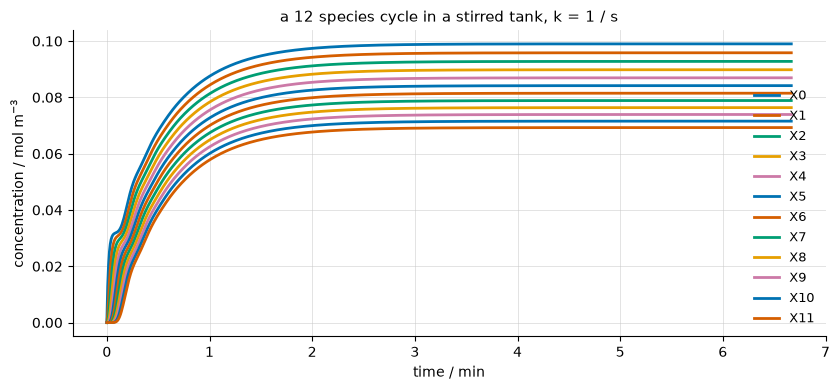

In [1]:
import utility.cycle_explorer as explorer

explorer.show_setting()

## What to watch

Two knobs, because either one alone proves nothing.

- **`n_species`** rotates the eigenvalues away from the real axis. It is the knob that decides whether trouble is *possible*.
- **`rate`** moves them outward along that circle. It is the knob that decides whether $h\lambda$ actually *lands* in the unstable region.

The second knob is the one that matters for reading the conclusion correctly. The unstable set of BDF5 is a **bounded island**, not a sector: the whole of it fits inside $|z| \leq 17.1$. So an eigenvalue sitting outside the $A(52^\circ)$ wedge is not simply dangerous — it is dangerous over a **window** of step sizes and harmless on both sides of it.

Here is what the eigenvalues predict before anything is simulated. The last column is that window: the step sizes at $k = 1\ \mathrm{s^{-1}}$ that would put the worst eigenvalue inside the island, computed by asking where the roots of the BDF5 characteristic polynomial leave the unit disk.

In [2]:
explorer.predictions()

,species in the cycle,angle / deg,outside A(52 deg),"h / s that destabilizes, at k = 1 / s"
0,3,29.5,no,"none, at any step size"
1,4,44.1,no,"none, at any step size"
2,6,58.4,yes,1.4 ... 4.2
3,12,71.5,yes,2 ... 12
4,24,75.5,yes,3.8 ... 27


Note that it is bounded at *both* ends, and that the short cycles have no window at all.

**`n_species = 3` and `4` are the control.** They sit inside the wedge, so no rate can destabilize them. If the rate knob changes the integrator's behaviour at $N = 12$ but not at $N = 3$, the cause is the geometry of the spectrum and not the speed of the chemistry.

In the record below: **`in the island`** applies the same stability test to the step size the integrator actually chose, and **`steps at order 5`** is the share of steps taken at the highest order — the first thing IDAS gives up when steps start failing.

In [3]:
from ipywidgets import interact

show_cycle = explorer.make_explorer()

interact(show_cycle, **show_cycle.sliders);

interactive(children=(SelectionSlider(continuous_update=False, description='n species', index=3, options=(('3'…

## What happened

**Step counts, every cycle length against every rate:**

| $N$ | $k$ = 0.5 | 1 | 2 | 3 | 5 | 8 | 20 | 100 | worst / slowest |
|---|---|---|---|---|---|---|---|---|---|
| 3 | 316 | 325 | 326 | 327 | 315 | 313 | 293 | 280 | — |
| 4 | 344 | 355 | 367 | 353 | 344 | 342 | 322 | 295 | — |
| 6 | 395 | 445 | 486 | 504 | 462 | **566** | 376 | 339 | ×1.43 |
| 12 | 483 | 561 | 650 | 711 | 703 | **723** | 628 | 478 | ×1.50 |
| 24 | 542 | 651 | 798 | 876 | 934 | 1038 | **1061** | 749 | ×1.96 |

**This is the one setting in the chapter where making a process faster costs more.** It is also the only one where the effect needed a second knob to exist at all: at $N = 3$ and $N = 4$ the step count *falls* monotonically as the reaction speeds up, exactly like the binding and reaction studies. Rotate the same spectrum off the real axis and the same rate sweep starts costing work.

**And the cost is a window, not a threshold.** Follow the $N = 12$ row: 483 steps at $k = 0.5$, rising to 723 at $k = 8$, then falling back to **478** at $k = 100$ — back to where it started, after passing through the expensive part. The bounded island predicts precisely this. A faster reaction is not monotonically worse; it is worse until $h\lambda$ has crossed the island and harmless once it is out the other side.

The mean BDF order tells the same story from the integrator's side, dropping from 5.00 to about 4.6 through the window and recovering past it.

<details>
<summary><b>Click to learn more: why the measured angles are smaller than 90° − 180°/N</b></summary>

The ideal circulant angles are 30°, 45°, 60°, 75° and 82.5°; the table reports 29.5°, 44.1°, 58.4°, 71.5° and 75.5°. The difference is the dilution term. The eigenvalues are shifted left by $Q/V = 0.033\ \mathrm{s^{-1}}$, which rotates them back *towards* the real axis, and the shift matters most where the eigenvalue is smallest.

The relevant eigenvalue has magnitude $2k\sin(\pi/N)$, so a long cycle has a *small* critical eigenvalue, not a large one. At $N = 24$ and $k = 1\ \mathrm{s^{-1}}$ it is only $0.26\ \mathrm{s^{-1}}$, within a factor of eight of the dilution rate, which is why the 82.5° cycle measures 75.5°. Instability needs $k \gtrsim 10\,(Q/V)$ before the dilution stops protecting the tank — which is also why the $N = 24$ row peaks at $k = 20$ rather than $k = 8$.

</details>

> **Take-away.** The chapter's result is not that fast processes are free. It is that the processes in a chromatography model happen to put their eigenvalues on the negative real axis, where BDF is stable at any magnitude — and that is a property of the physics, not of the integrator. Build a system whose spectrum leaves that axis, as an autocatalytic or oscillating reaction network does, and the step size becomes stability-limited rather than accuracy-limited. Even then it costs a factor of two, over a bounded window of rates, in a model constructed for the purpose. That is how hard it is to make CADET stiff.